# EKF de azúcar total · química del 17 y del 17_2

Se comparan las dos calibraciones S ya guardadas en el notebook 17_2, para LAB016–024. Se usa el protocolo cronológico del EKF 14, con el modelo de seis estados del 06 y la misma pareja de gas del 17_2. Ambas corridas usan los mismos estados iniciales, pulsos, ventanas de CO₂ y covarianzas de arranque. El ruido de proceso usa las intensidades del 06 y el mapeo con el estado y rendimiento de cada ajuste. R = (0,04 g/(L·h))².

La temperatura es la mediana del último minuto completado. Se asimilan medias observadas de ventanas cerradas de 30 min con al menos 30 lecturas y hueco máximo de dos minutos, incluidos los extremos. Se corrige si dos ventanas consecutivas son válidas y alcanzan 0,05 g/(L·h). La química y biomasa posteriores a la inicial se usan para evaluar.

In [1]:
from pathlib import Path
from dataclasses import replace
import ast
import json
import sys

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd

ROOT=next(path for path in [Path.cwd(),*Path.cwd().parents] if (path/'src/wine_fermentation').is_dir())
sys.path.insert(0,str(ROOT/'src'))
sys.dont_write_bytecode=True
from wine_fermentation import model as kin
from wine_fermentation.comparison import chemical_observations, CHEMICAL_COLUMNS
from wine_fermentation.models.historical.calibration import load

fit_source = ROOT / "notebooks/17_2_zenteno_single_sugar_legacy_biomass_weight.source.ipynb"
fit_path = fit_source.with_name(fit_source.name.replace(".source.", ".executed."))
fit_nb = nbformat.read(fit_path, 4)
fit_inputs = nbformat.read(fit_source, 4)
assert [c.source for c in fit_nb.cells] == [c.source for c in fit_inputs.cells]

def literal_from_fit(name):
    [assignment] = [node for cell in fit_inputs.cells if cell.cell_type == "code"
                    for node in ast.parse(cell.source).body if isinstance(node, ast.Assign)
                    and any(isinstance(target, ast.Name) and target.id == name for target in node.targets)]
    return ast.literal_eval(assignment.value)

tag = "PARÁMETROS S 17_2"
[payload] = [item.text.split(tag, 1)[1].lstrip()
             for cell in fit_nb.cells for item in cell.get("outputs", [])
             if item.output_type == "stream" and tag in item.text]
base = literal_from_fit("theta")
fixed = {name: base[name] for name in ("Kn0", "Kd0", "m0")}
fixed["Yxs"] = 1/(1/base["Yxg"] + 1/base["Yxf"])
parameters = {"S 17": {**literal_from_fit("ps_original"), **fixed},
              "S 17_2": {**json.JSONDecoder().raw_decode(payload)[0], **fixed}}
assert parameters["S 17"]["Kie0"] == parameters["S 17_2"]["Kie0"] == base["Kie0"]
KLA, GAIN = literal_from_fit("HOLDOUT_GAS_PARAMS")
display(pd.DataFrame(parameters))
print("Y_X/N original y nuevo:", *(p["Yxn"] for p in parameters.values()))
print("kLa y ganancia:", KLA, GAIN)

# The EKF 14 uses the chronological inputs and temperature policy of diagnostics 25.
data_source = ROOT / "notebooks/diagnostics/25_zenteno_azucar_total_temperatura_causal.source.ipynb"
inputs_nb = nbformat.read(data_source, 4)

def definitions(notebook,names):
    result={}
    for cell in notebook.cells:
        if cell.cell_type=='code':
            for node in ast.parse(cell.source).body:
                if isinstance(node,ast.FunctionDef) and node.name in names:
                    result[node.name]=ast.get_source_segment(cell.source,node)
    assert result.keys()==set(names)
    return result

thermal_profiles={}
for function in definitions(inputs_nb,['register_temperature','causal_temperature']).values():
    exec(compile(function,str(data_source),'exec'))


Y_X/N original y nuevo: 6.497331613020979 5.31642216832974
kLa y ganancia: 0.13796553316180868 0.6586783889606775


,S 17,S 17_2
mu0,0.090851,0.085183
betaS0,0.818966,0.899043
Ks0,23.046565,18.439784
Kie0,96.265166,96.265166
Yxn,6.497332,5.316422
Yes,0.489318,0.484283
Kn0,0.008258,0.008258
Kd0,0.000440,0.000440
m0,0.018339,0.018339
Yxs,0.516507,0.516507


## Entradas comunes y ventanas de CO₂

Se conservan las entradas del EKF 14, incluidas las condiciones iniciales, pulsos y horizontes. Cada vector químico se evalúa en las mismas ventanas observadas.

In [2]:
LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018','LAB022','LAB023','LAB024']
historical=LABS[:6]
gas_calibration=LABS[:3]
v=load(ROOT)
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',
                usecols=['lab','time_h','record_kind','remaining_volume_L'])
batches={}
volumes={}

def volume_function(event_times,event_volumes,initial):
    def volume(times):
        return np.r_[initial,event_volumes][np.searchsorted(event_times,np.asarray(times),side='right')]
    return volume

for lab in historical:
    batch=v.batches[lab]
    events=raw.loc[raw.lab.eq(lab)&raw.record_kind.eq('withdrawal_after')].sort_values('time_h')
    volume=volume_function(events.time_h.to_numpy(),events.remaining_volume_L.to_numpy(),2.)
    volumes[lab]=volume
    if lab in gas_calibration:
        batch=replace(batch,pulses={**batch.pulses,'N':tuple((t,d*2/float(volume(t))) for t,d in batch.pulses['N'])})
    if lab=='LAB017':
        schedule=batch.pulses['N']
        batch=replace(batch,pulses={**batch.pulses,'N':((min(t for t,_ in schedule),sum(d for _,d in schedule)),)})
    if lab=='LAB021':
        batch=replace(batch,initials={**batch.initials,'X':.27})
    batches[lab]=batch
    register_temperature(lab,v.raw_temperature[lab])

# Reuse the recent batch preparation, which defines the same sample support and initial values.
[recent_inputs]=[cell.source for cell in inputs_nb.cells if 'def read_holdout_backup(' in cell.source]
recent=recent_inputs[:recent_inputs.index('    raw = holdout_raw_flow')]
recent+='    volumes[lab]=volume_function(withdrawals,-.05*np.arange(1,len(withdrawals)+1)+initial_volume,initial_volume)\n'
exec(compile(recent,str(data_source),'exec'))
batches.update(holdout_batches)
assert set(batches)==set(LABS)

def sensor_windows(raw_flow,volume,start,end):
    raw_flow=raw_flow.dropna(subset=['t_h','flow_sccm']).sort_values('t_h')
    ids=np.ceil(raw_flow.t_h/.5-1e-10).astype(int)
    grouped={key: frame for key,frame in raw_flow.groupby(ids)}
    rows=[]
    for key in range(1,int(np.floor(end/.5+1e-10))+1):
        stop=key*.5
        window=grouped.get(key)
        valid=False
        measured=np.nan
        if window is not None and len(window):
            times=window.t_h.to_numpy()
            valid=(stop-.5>=start and len(times)>=30 and
                   np.diff(np.r_[stop-.5,times,stop]).max()<=2/60+1e-10)
            if valid:
                measured=float(np.mean(window.flow_sccm.to_numpy()*mass_factor/volume(times)))
        rows.append((stop,measured,valid))
    sensor=pd.DataFrame(rows,columns=['t_h','measured','valid']).set_index('t_h')
    usable=sensor.valid&sensor.measured.ge(.05)
    sensor['update']=usable&usable.shift(fill_value=False)
    return sensor

data={}
scoring_samples={}
support_audit=[]
for lab,batch in batches.items():
    start=float(batch.time[0])
    end=float(v.horizons[lab]) if lab in historical else holdout_horizon
    if lab in historical:
        flow=v.raw_co2[lab]
        samples=(chemical_observations(v.chem,lab,'X') if lab in gas_calibration
                 else v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h','X_viable_g_l']))
    else:
        flow=holdout_raw_flow.loc[holdout_raw_flow.lab.eq(lab)].rename(columns={'h':'t_h'})
        samples=holdout_biomass.loc[holdout_biomass.lab.eq(lab)&holdout_biomass['sample'].ne('01')]
        samples=samples.rename(columns={'hours':'t_h','X_g_L':'X_viable_g_l'})
    samples=samples.loc[(samples.t_h>start)&(samples.t_h<=end),['t_h','X_viable_g_l']]
    scoring_samples[lab]=samples.sort_values('t_h').reset_index(drop=True)
    sensor=sensor_windows(flow,volumes[lab],start,end)
    assert sensor['update'].any() and len(samples)>0
    initial=batch.initials
    x0=np.array([initial['X'],initial['N'],initial['G']+initial['F'],initial['E'],0.,0.])
    P0=np.diag([max(.03,.2*x0[0])**2,.015**2,25.,4.,0.,0.])
    pulses={round(t,10): dose for t,dose in batch.pulses['N'] if start<t<=end}
    grid=np.unique(np.round(np.r_[np.arange(start,end,1/12),list(pulses),sensor.index,end],10))
    grid=grid[grid>=start-1e-10]
    assert np.isclose(grid[0],start)
    assert thermal_profiles[lab][0][0]<=start
    data[lab]=dict(grid=grid,initial=x0,P0=P0,pulses=pulses,sensor=sensor,batch=batch)
    support_audit.append(dict(LAB=lab,inicio=start,fin=end,n_biomasa=len(samples),
                              ventanas_válidas=int(sensor.valid.sum()),correcciones=int(sensor['update'].sum())))
display(pd.DataFrame(support_audit).set_index('LAB'))


,inicio,fin,n_biomasa,ventanas_válidas,correcciones
LAB,,,,,
LAB019,0.00,166.000000,10,332,217
LAB020,0.00,172.333333,10,344,223
LAB021,0.00,166.000000,10,332,166
LAB016,0.00,151.100000,3,302,249
LAB017,0.00,141.000000,3,282,213
LAB018,0.00,141.000000,3,282,237
LAB022,0.25,190.000000,5,378,247
LAB023,0.25,190.000000,5,378,294
LAB024,0.25,190.000000,5,378,253


## Reproducción del EKF

Se reutilizan las tasas, transferencia de gas, diferencias finitas y ruido de proceso del EKF-S del notebook 06. RK4 integra hasta el siguiente minuto, pulso o cierre de ventana. La temperatura de cada intervalo es la disponible al comienzo de ese intervalo. La actualización usa la forma de Joseph y reinicia el acumulador en todos los cierres. Para evaluar una muestra entre pasos se propaga desde el último estado disponible hasta su hora.

In [3]:
from types import FunctionType

ekf_path=ROOT/'notebooks/EKF/06_zenteno_single_sugar_variable_solubility.source.ipynb'
ekf_source=nbformat.read(ekf_path,4)
[s_cell]=[cell.source for cell in ekf_source.cells if "PS={'mu0'" in cell.source]
s_functions=definitions(nbformat.v4.new_notebook(cells=[nbformat.v4.new_code_cell(s_cell)]),
                        ['rates_ekf','jacobian','noise_matrix'])
gas_functions=definitions(ekf_source,['co2_saturation','gas_exchange'])
SCALE_EKF=np.array([.3,.25,160.,15.,.2,1.])
R_CO2=.04**2
H=np.array([0.,0.,0.,0.,0.,2.])
IDENTITY=np.eye(6)

def thermal_steps(batch,start,end):
    available=thermal_profiles[batch.batch][0]
    left=np.searchsorted(available,start+1e-10,side='right')
    right=np.searchsorted(available,end-1e-10,side='left')
    edges=np.r_[start,available[left:right],end]
    return tuple(zip(edges[:-1],np.diff(edges),causal_temperature(batch,edges[:-1]+1e-10)))

def make_model(p):
    namespace=dict(np=np,KLA=KLA,GAIN=GAIN,PCO2_BAR=1.,PS=p,theta=p,YXS=p['Yxs'],SCALE_EKF=SCALE_EKF)
    for function in [*gas_functions.values(),*s_functions.values()]:
        exec(compile(function,str(ekf_path),'exec'),namespace)
    rates=namespace['rates_ekf']
    def transition(z,start,end,steps,S0):
        w=np.atleast_2d(z)*SCALE_EKF
        for time,dt,temp in steps:
            # Split long gaps too, even when the held temperature stays unchanged.
            count=max(1,int(np.ceil(dt*60-1e-7)))
            h=dt/count
            for j in range(count):
                t=time+j*h
                a=rates(w,t,temp,S0)
                b=rates(w+h*a/2,t+h/2,temp,S0)
                c=rates(w+h*b/2,t+h/2,temp,S0)
                d=rates(w+h*c,t+h,temp,S0)
                w=np.maximum(w+h*(a+2*b+2*c+d)/6,0.)
        return w/SCALE_EKF
    namespace['transition']=transition
    return transition,namespace['jacobian'],namespace['noise_matrix']

def replay(inputs,model):
    advance,jacobian,noise=model
    grid=inputs['grid']
    batch=inputs['batch']
    sensor=inputs['sensor']
    windows={t: (row.measured,row.valid,row['update']) for t,row in sensor.iterrows()}
    y0=inputs['initial']
    S0=y0[2]
    z=y0/SCALE_EKF
    free=z.copy()
    P=inputs['P0']/np.outer(SCALE_EKF,SCALE_EKF)
    states=[]
    readings=[]
    for i,time in enumerate(grid):
        if i:
            start=grid[i-1]
            steps=thermal_steps(batch,start,time)
            process=noise(z*SCALE_EKF,steps[0][2],S0)*(time-start)
            z,J=jacobian(z,start,time,steps,S0)
            P=J@P@J.T+process
            P=(P+P.T)/2
            free=advance(free,start,time,steps,S0)[0]
        if time in inputs['pulses']:
            dose=inputs['pulses'][time]/SCALE_EKF[1]
            z[1]+=dose
            free[1]+=dose
        if time in windows:
            measured,valid,update=windows[time]
            predicted=float(H@z)
            nis=np.nan
            clipped=0
            if update:
                variance=float(H@P@H+R_CO2)
                assert variance>0
                gain=P@H/variance
                innovation=measured-predicted
                updated=z+gain*innovation
                clipped=int(np.count_nonzero(updated[:5]<0))
                z=np.maximum(updated,0.)
                B=IDENTITY-np.outer(gain,H)
                P=B@P@B.T+np.outer(gain,gain)*R_CO2
                P=(P+P.T)/2
                nis=innovation**2/variance
            readings.append((time,measured,valid,update,predicted,float(H@free),nis,clipped))
            z[5]=free[5]=0.
            P[5,:]=P[:,5]=0.
        assert np.isfinite(z).all() and np.linalg.eigvalsh(P).min()>=-1e-7
        states.append(np.stack([z,free]))
    readings=pd.DataFrame(readings,columns=['t_h','measured','valid','update','forecast','free','NIS','recortes'])
    np.testing.assert_array_equal(readings['update'],sensor['update'])
    return np.stack(states),readings

models={label:make_model(vector) for label,vector in parameters.items()}
results={}
for label,model in models.items():
    results[label]={}
    for lab,inputs in data.items():
        results[label][lab]=replay(inputs,model)
        print(label,lab,'completado',flush=True)


S 17 LAB019 completado
S 17 LAB020 completado
S 17 LAB021 completado
S 17 LAB016 completado
S 17 LAB017 completado
S 17 LAB018 completado
S 17 LAB022 completado
S 17 LAB023 completado
S 17 LAB024 completado
S 17_2 LAB019 completado
S 17_2 LAB020 completado
S 17_2 LAB021 completado
S 17_2 LAB016 completado
S 17_2 LAB017 completado
S 17_2 LAB018 completado
S 17_2 LAB022 completado
S 17_2 LAB023 completado
S 17_2 LAB024 completado


## Biomasa en LAB016–024

El RMSE y el sesgo se calculan con muestras posteriores a la inicial. La columna «Libre» usa la misma dinámica y temperatura con la corrección desactivada. El exceso medio promedia la parte positiva del error en todas las muestras. Los promedios dan el mismo peso a cada lote.

BIOMASS_BY_LAB [{"LAB":"LAB019","ajuste":"S 17","modo":"EKF","n":10,"RMSE":0.7075385461,"MAE":0.5624716231,"sesgo":0.1075028081,"exceso":0.3349872156},{"LAB":"LAB019","ajuste":"S 17","modo":"Libre","n":10,"RMSE":0.4734403824,"MAE":0.3505326905,"sesgo":0.3223809888,"exceso":0.3364568396},{"LAB":"LAB019","ajuste":"S 17_2","modo":"EKF","n":10,"RMSE":0.6172039985,"MAE":0.4777837385,"sesgo":-0.062734424,"exceso":0.2075246573},{"LAB":"LAB019","ajuste":"S 17_2","modo":"Libre","n":10,"RMSE":0.3504724414,"MAE":0.2579324332,"sesgo":0.1169164904,"exceso":0.1874244618},{"LAB":"LAB020","ajuste":"S 17","modo":"EKF","n":10,"RMSE":0.6096221919,"MAE":0.4218595793,"sesgo":-0.1626076756,"exceso":0.1296259518},{"LAB":"LAB020","ajuste":"S 17","modo":"Libre","n":10,"RMSE":0.5384915532,"MAE":0.3413328322,"sesgo":-0.0955479831,"exceso":0.1228924246},{"LAB":"LAB020","ajuste":"S 17_2","modo":"EKF","n":10,"RMSE":0.6194232703,"MAE":0.4596015647,"sesgo":-0.2799995935,"exceso":0.0898009856},{"LAB":"LAB020","ajuste"

modo,EKF,Libre,EKF,Libre
ajuste,S 17,S 17,S 17_2,S 17_2
LAB,,,,
LAB019,0.7075,0.4734,0.6172,0.3505
LAB020,0.6096,0.5385,0.6194,0.5446
LAB021,1.0219,0.5272,0.7509,0.5220
LAB016,0.4857,0.3538,0.3500,0.2684
LAB017,0.7654,0.5328,0.6093,0.4255
LAB018,0.4380,0.3518,0.3476,0.3537
LAB022,0.8432,0.4304,0.4017,0.3063
LAB023,0.7820,0.5666,0.5572,0.3452


RMSE     MAE   sesgo  exceso
modo  ajuste                                
EKF   S 17    0.7390  0.5934  0.4653  0.5293
      S 17_2  0.5563  0.4519  0.2792  0.3655
Libre S 17    0.5089  0.4160  0.3448  0.3804
      S 17_2  0.4111  0.3470  0.1848  0.2659

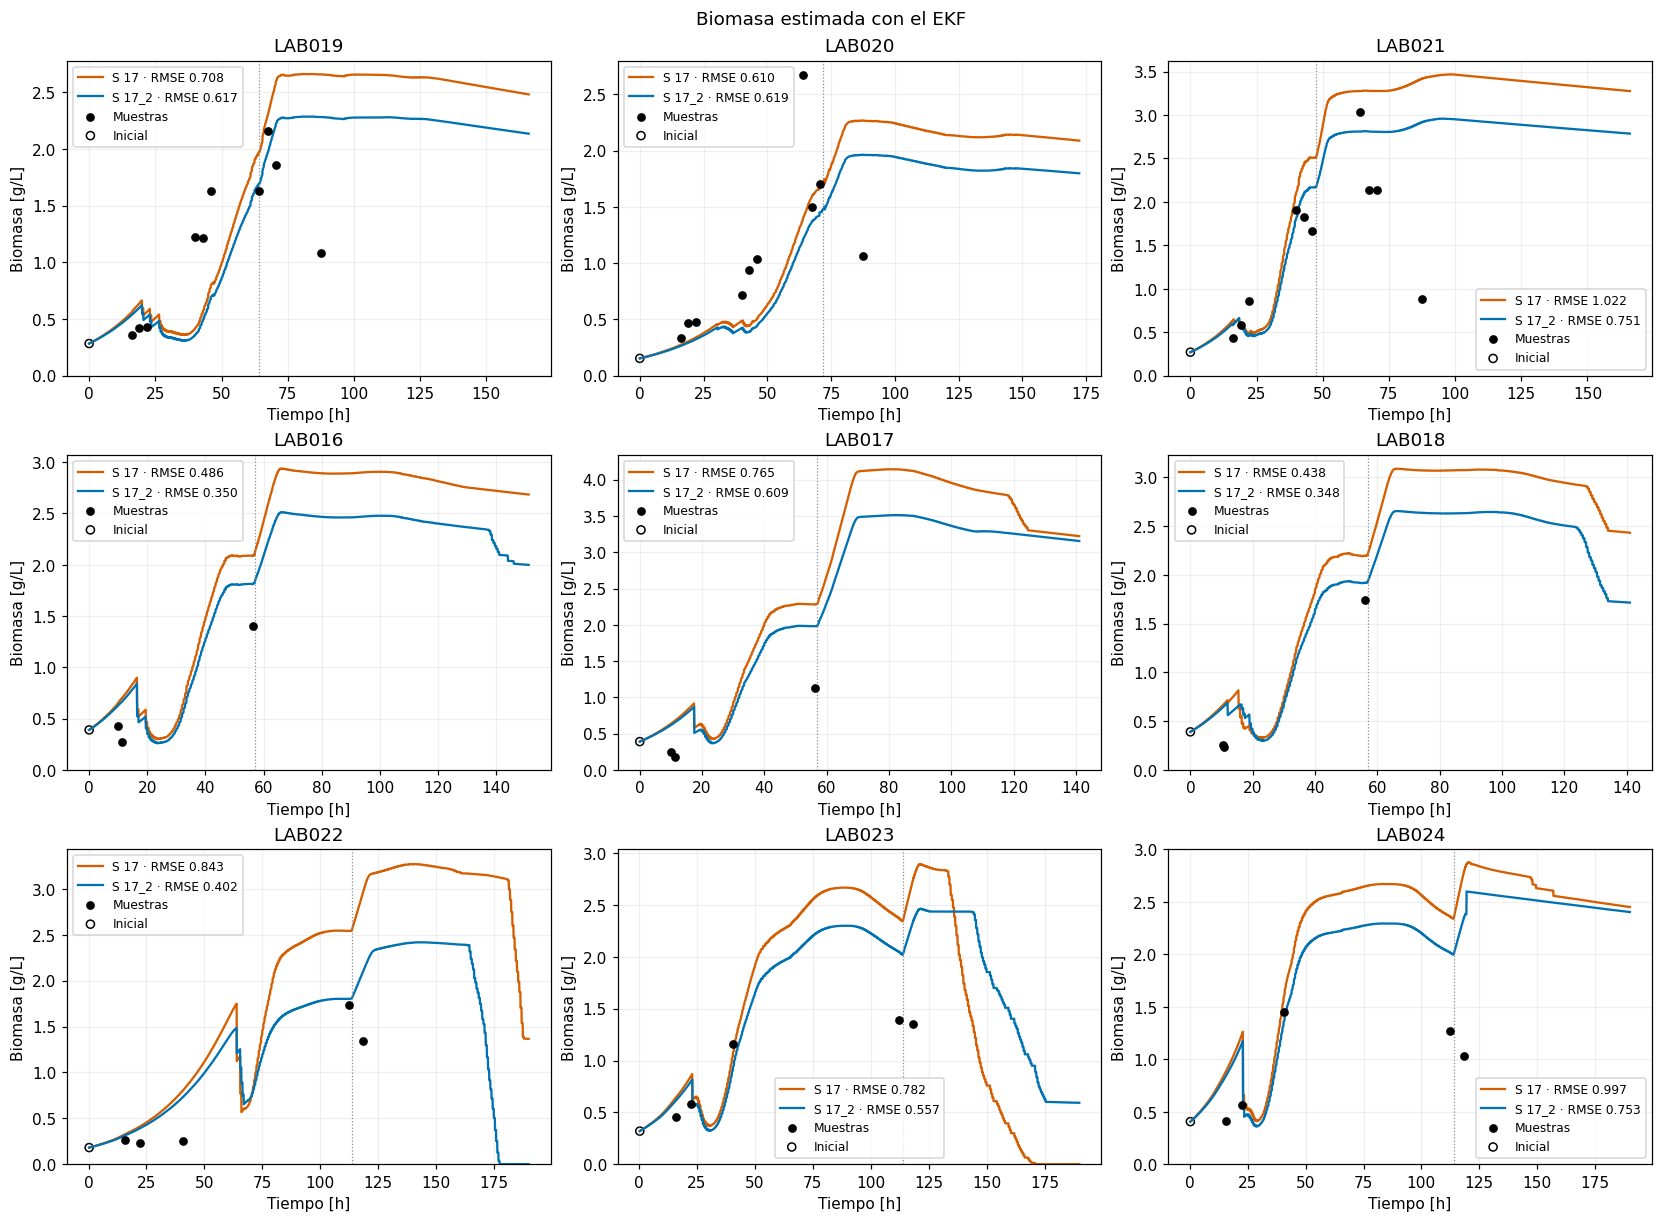

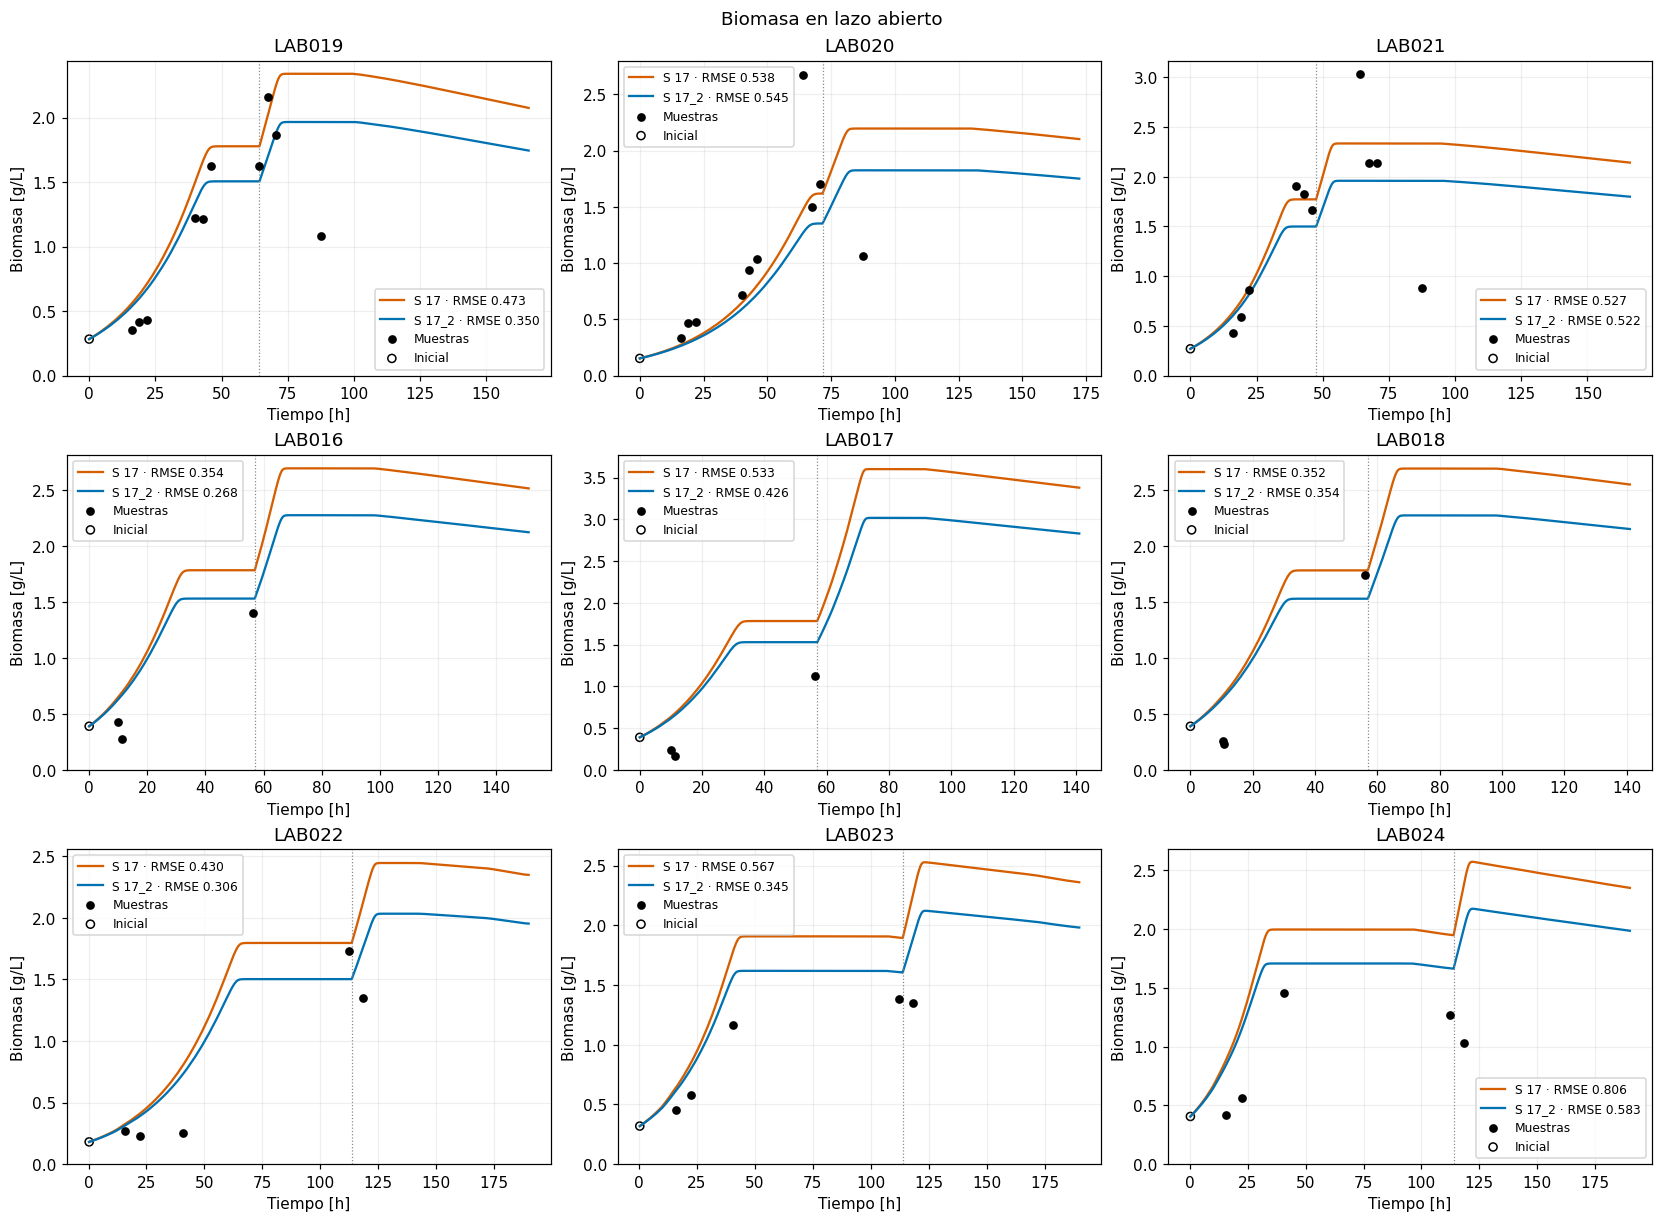

In [4]:
labels=list(parameters)
styles={labels[0]:dict(color='#D55E00'),labels[1]:dict(color='#0072B2')}

def states_at_samples(inputs,model,states,times,state_index=0):
    grid=inputs['grid']
    advance=model[0]
    out=[]
    for time in times:
        index=np.searchsorted(grid,time+1e-10,side='right')-1
        assert index>=0
        last=grid[index]
        points=states[index]
        if time>last+1e-10:
            points=advance(points,last,time,thermal_steps(inputs['batch'],last,time),inputs['initial'][2])
        out.append(points[:,state_index]*SCALE_EKF[state_index])
    return np.array(out)

rows=[]
for lab in LABS:
    samples=scoring_samples[lab]
    y=samples.X_viable_g_l.to_numpy()
    for label in labels:
        predictions=states_at_samples(data[lab],models[label],results[label][lab][0],samples.t_h)
        for index,mode in enumerate(('EKF','Libre')):
            error=predictions[:,index]-y
            rows.append(dict(LAB=lab,ajuste=label,modo=mode,n=len(y),
                             RMSE=np.sqrt(np.mean(error**2)),MAE=np.mean(abs(error)),
                             sesgo=np.mean(error),exceso=np.maximum(error,0.).mean()))
metrics=pd.DataFrame(rows)
wide=metrics.pivot(index='LAB',columns=['modo','ajuste'],values='RMSE')
display(wide.reindex(LABS).round(4))
averages=metrics.groupby(['modo','ajuste'])[['RMSE','MAE','sesgo','exceso']].mean()
display(averages.round(4))
print('BIOMASS_BY_LAB',metrics.to_json(orient='records'))
print('BIOMASS_AVERAGES',averages.reset_index().to_json(orient='records'))

def biomass_panels(mode_index,title):
    fig,axes=plt.subplots(3,3,figsize=(15,11),layout='constrained')
    for ax,lab in zip(axes.flat,LABS):
        inputs=data[lab]
        grid=inputs['grid']
        samples=scoring_samples[lab]
        for label in labels:
            scores=metrics.loc[metrics.LAB.eq(lab)&metrics.ajuste.eq(label)&metrics.modo.eq(('EKF','Libre')[mode_index])]
            score=scores.RMSE.iloc[0]
            x=results[label][lab][0][:,mode_index,0]*SCALE_EKF[0]
            ax.plot(grid,x,label=f'{label} · RMSE {score:.3f}',**styles[label])
        ax.scatter(samples.t_h,samples.X_viable_g_l,color='black',s=22,zorder=4,label='Muestras')
        ax.scatter(grid[0],inputs['initial'][0],facecolors='none',edgecolors='black',s=28,label='Inicial')
        for pulse in inputs['pulses']:
            ax.axvline(pulse,c='#888888',ls=':',lw=.8)
        ax.set(title=lab,xlabel='Tiempo [h]',ylabel='Biomasa [g/L]',ylim=(0,None))
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.show()

biomass_panels(0,'Biomasa estimada con el EKF')
biomass_panels(1,'Biomasa en lazo abierto')


## Pronóstico de CO₂ y correcciones

El RMSE usa el pronóstico previo a la actualización en las ventanas asimiladas. El NIS es el cuadrado de la innovación dividido por su varianza predicha. Los recortes cuentan componentes de estado negativos tras la corrección.

CO2_AVERAGES [{"ajuste":"S 17","RMSE":0.1182316651,"sesgo":-0.0431769042,"recortes":112.3333333333},{"ajuste":"S 17_2","RMSE":0.1228456177,"sesgo":-0.0431267883,"recortes":96.6666666667}]


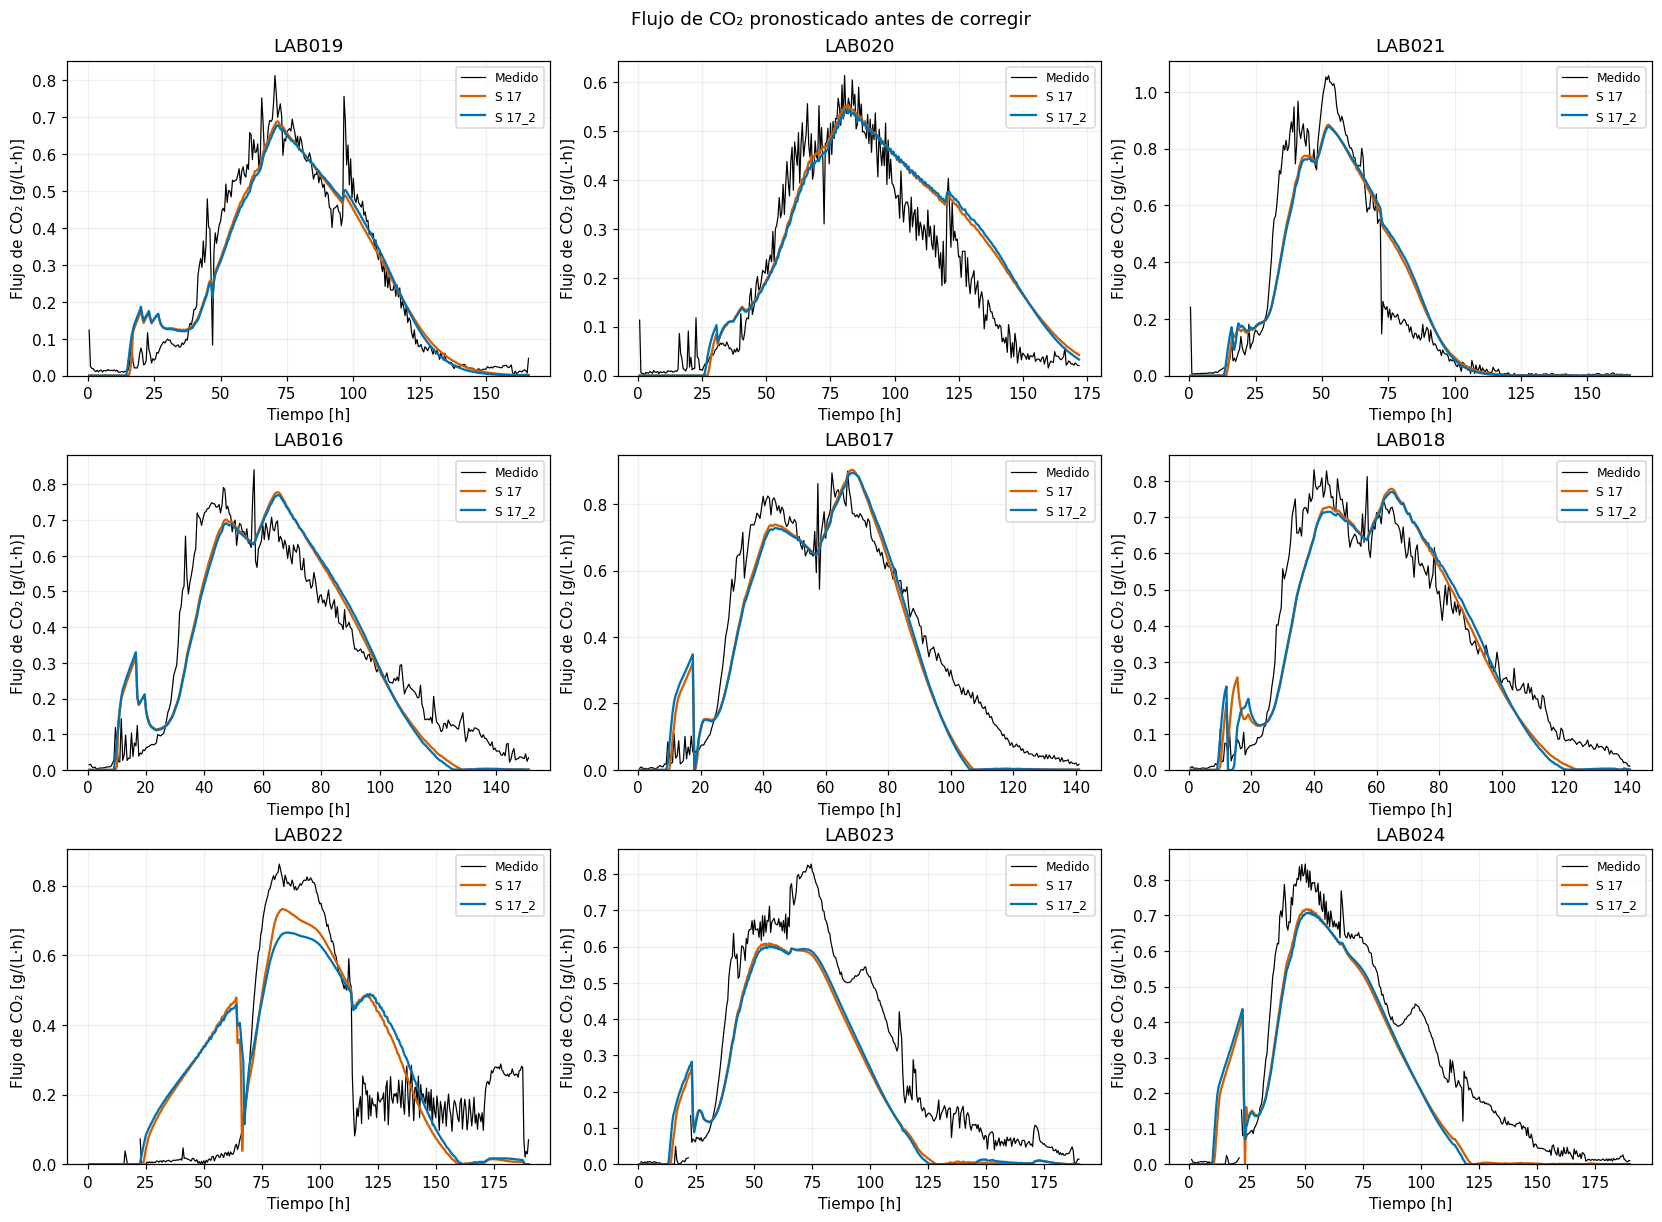

,LAB,ajuste,n,RMSE,sesgo,NIS_mediano,recortes
0,LAB019,S 17,217,0.0684,-0.0175,0.3358,40
1,LAB019,S 17_2,217,0.0705,-0.0182,0.3514,39
2,LAB020,S 17,223,0.0813,0.0345,0.8575,8
3,LAB020,S 17_2,223,0.0865,0.0341,0.9451,8
4,LAB021,S 17,166,0.1496,-0.0006,1.4453,26
5,LAB021,S 17_2,166,0.1579,0.0025,1.5369,25
6,LAB016,S 17,249,0.1015,-0.0255,1.5799,117
7,LAB016,S 17_2,249,0.1067,-0.0273,1.8589,102
8,LAB017,S 17,213,0.1167,-0.0667,1.5946,118
9,LAB017,S 17_2,213,0.1198,-0.0667,1.7891,136


In [5]:
gas_metrics=[]
fig,axes=plt.subplots(3,3,figsize=(15,11),layout='constrained')
for ax,lab in zip(axes.flat,LABS):
    sensor=data[lab]['sensor']
    ax.plot(sensor.index,sensor.measured,c='black',lw=.8,label='Medido')
    for label in labels:
        readings=results[label][lab][1]
        active=readings.loc[readings['update']]
        error=active.forecast-active.measured
        gas_metrics.append(dict(LAB=lab,ajuste=label,n=len(active),RMSE=np.sqrt(np.mean(error**2)),
                                sesgo=error.mean(),NIS_mediano=active.NIS.median(),
                                recortes=int(active.recortes.sum())))
        ax.plot(readings.t_h,readings.forecast,label=label,**styles[label])
    ax.set(title=lab,xlabel='Tiempo [h]',ylabel='Flujo de CO₂ [g/(L·h)]',ylim=(0,None))
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.suptitle('Flujo de CO₂ pronosticado antes de corregir')
plt.show()
gas_metrics=pd.DataFrame(gas_metrics)
assert gas_metrics.groupby('LAB').n.nunique().eq(1).all()
display(gas_metrics.round(4))
print('CO2_AVERAGES',gas_metrics.groupby('ajuste')[['RMSE','sesgo','recortes']].mean().reset_index().to_json(orient='records'))


## YAN y azúcar total estimados

modo        EKF    Libre      EKF    Libre
ajuste     S 17     S 17   S 17_2   S 17_2
LAB                                       
LAB016  0.48574  0.35382  0.34998  0.26842
LAB017  0.76541  0.53282  0.60929  0.42554
LAB018  0.43802  0.35175  0.34763  0.35373
LAB019  0.70754  0.47344  0.61720  0.35047
LAB020  0.60962  0.53849  0.61942  0.54464
LAB021  1.02194  0.52721  0.75094  0.52202
LAB022  0.84317  0.43036  0.40169  0.30635
LAB023  0.78202  0.56660  0.55720  0.34524
LAB024  0.99730  0.80568  0.75338  0.58316
   LAB ajuste   n    RMSE    sesgo  NIS_mediano  recortes
LAB019   S 17 217 0.06836 -0.01750      0.33578        40
LAB019 S 17_2 217 0.07054 -0.01818      0.35144        39
LAB020   S 17 223 0.08126  0.03450      0.85753         8
LAB020 S 17_2 223 0.08651  0.03413      0.94508         8
LAB021   S 17 166 0.14958 -0.00059      1.44528        26
LAB021 S 17_2 166 0.15789  0.00251      1.53688        25
LAB016   S 17 249 0.10149 -0.02551      1.57992       117
LAB016 S 17_2 249 0.

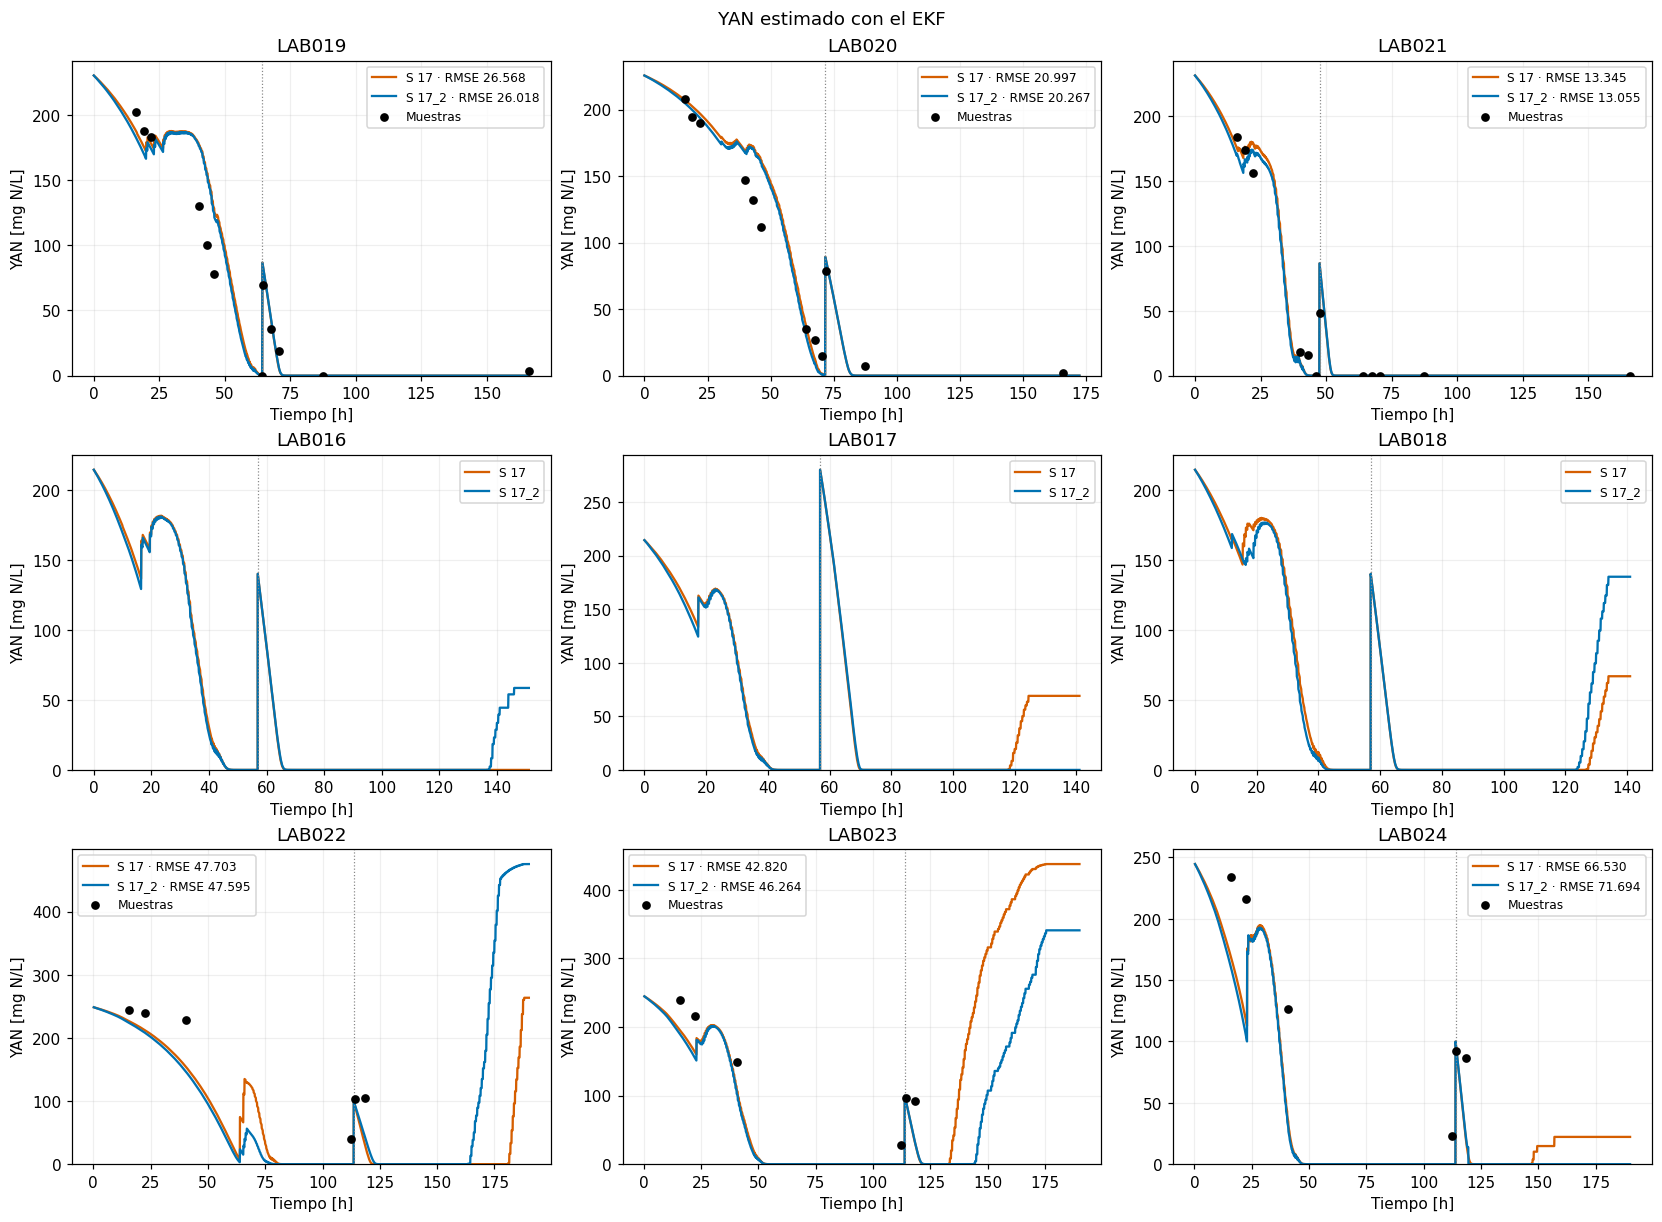

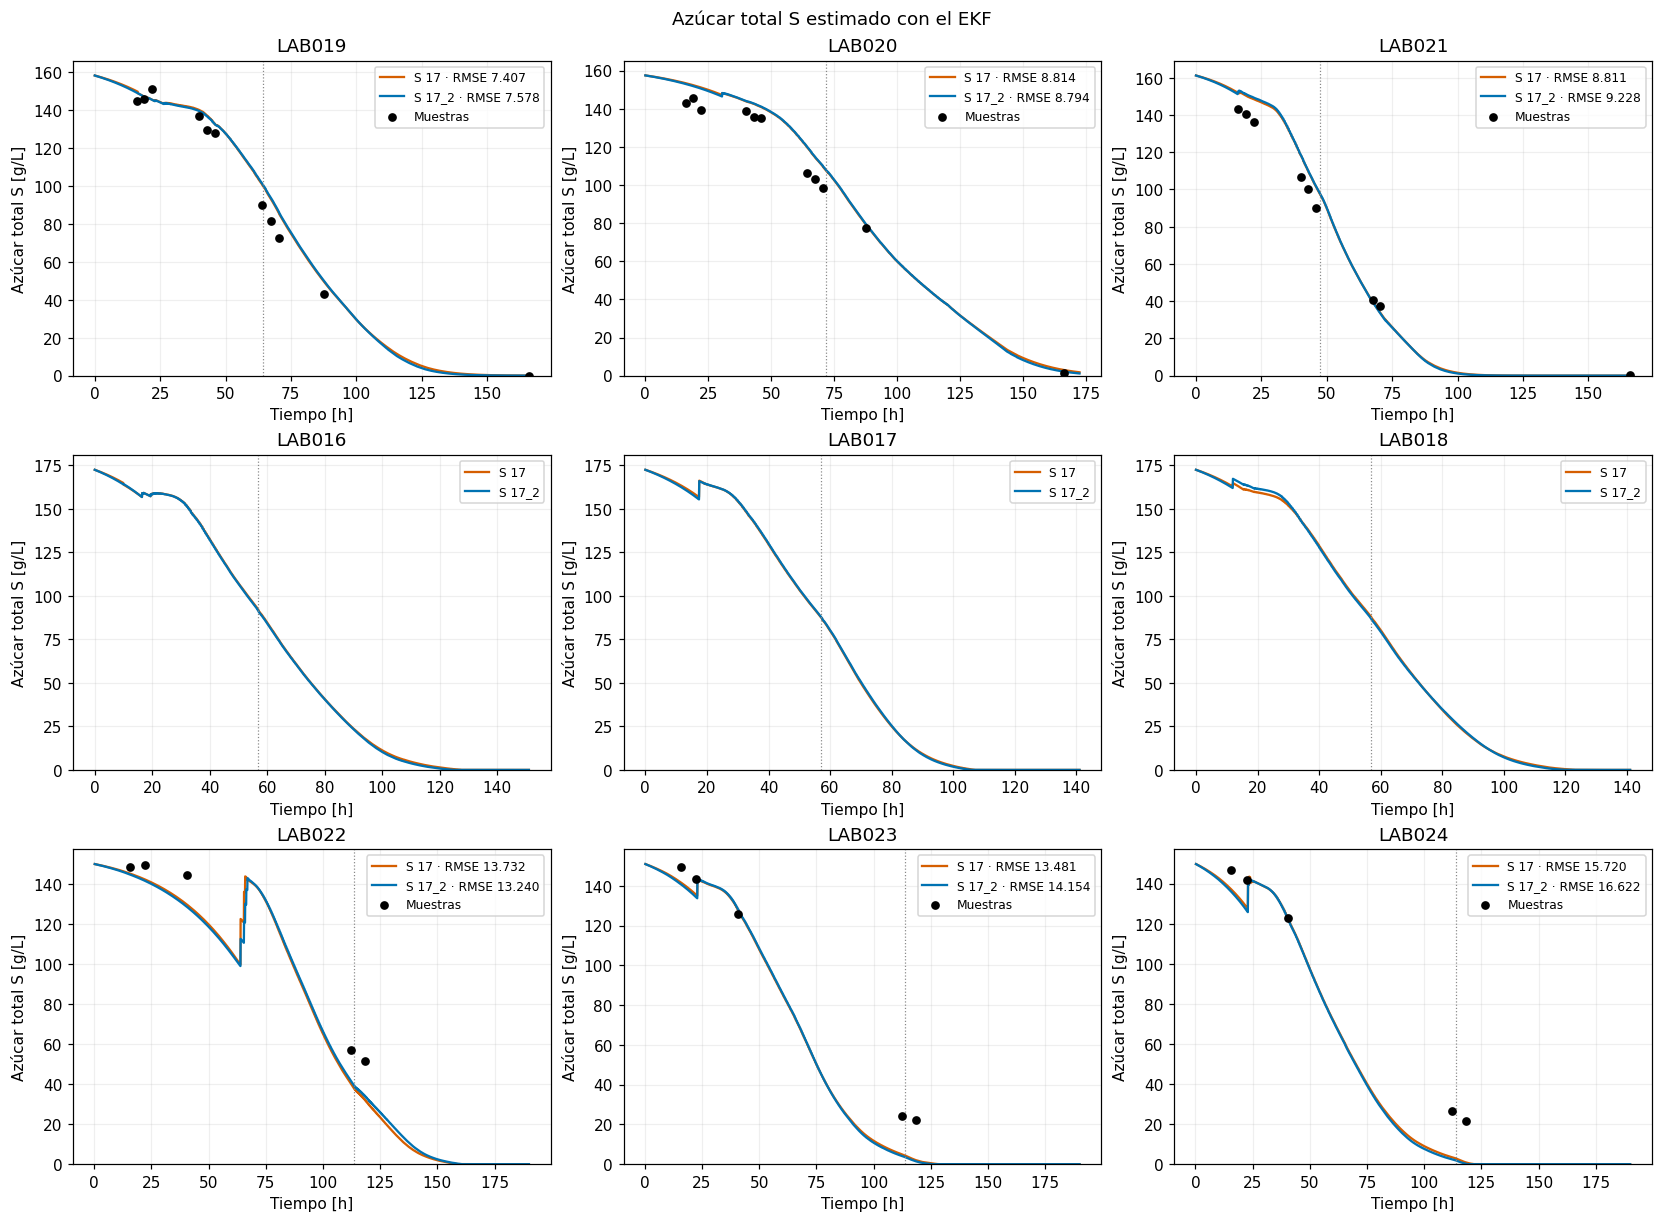

,LAB,Estado,Unidad,ajuste,n,RMSE,sesgo
0,LAB019,N,mg N/L,S 17,12,26.5679,10.5836
1,LAB019,N,mg N/L,S 17_2,12,26.0178,8.8268
2,LAB020,N,mg N/L,S 17,12,20.9969,8.4194
3,LAB020,N,mg N/L,S 17_2,12,20.2668,6.3252
4,LAB021,N,mg N/L,S 17,12,13.3454,2.4708
5,LAB021,N,mg N/L,S 17_2,12,13.0552,0.8045
6,LAB022,N,mg N/L,S 17,6,47.7030,-40.8201
7,LAB022,N,mg N/L,S 17_2,6,47.5946,-40.9382
8,LAB023,N,mg N/L,S 17,6,42.8203,-38.5254
9,LAB023,N,mg N/L,S 17_2,6,46.2637,-41.6075


In [6]:
chem_rows = []
for state, state_index, title, unit, factor, recent_column in (
    ("N", 1, "YAN", "mg N/L", 1000., "YAN for plot"),
    ("GF", 2, "Azúcar total S", "g/L", 1., "GLU-FRU-320"),
):
    fig, axes = plt.subplots(3, 3, figsize=(15, 11), layout="constrained")
    for ax, lab in zip(axes.flat, LABS):
        inputs = data[lab]
        grid = inputs["grid"]
        if lab in historical:
            samples = chemical_observations(v.chem, lab, state)
            times = samples.t_h.to_numpy()
            observed = samples[CHEMICAL_COLUMNS[state]].to_numpy() * factor
        else:
            samples = holdout_chemistry.loc[holdout_chemistry.lab.eq(lab) &
                                             holdout_chemistry["sample"].ne("01")].dropna(subset=[recent_column])
            times = samples.hours.to_numpy()
            observed = samples[recent_column].to_numpy()
        valid = (times > grid[0]) & (times <= grid[-1])
        times, observed = times[valid], observed[valid]
        for label in labels:
            states = results[label][lab][0]
            legend_label = label
            if len(times):
                predicted = states_at_samples(inputs, models[label], states, times, state_index)[:, 0] * factor
                error = predicted - observed
                score = np.sqrt(np.mean(error**2))
                chem_rows.append(dict(LAB=lab, Estado=state, Unidad=unit, ajuste=label, n=len(error),
                                      RMSE=score, sesgo=error.mean()))
                legend_label += f" · RMSE {score:.3f}"
            ax.plot(grid, states[:, 0, state_index] * SCALE_EKF[state_index] * factor,
                    label=legend_label, **styles[label])
        if len(times):
            ax.scatter(times, observed, c="black", s=22, zorder=4, label="Muestras")
        for pulse in inputs["pulses"]:
            ax.axvline(pulse, c="#888888", ls=":", lw=.8)
        ax.set(title=lab, xlabel="Tiempo [h]", ylabel=f"{title} [{unit}]", ylim=(0, None))
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
    fig.suptitle(f"{title} estimado con el EKF")
    plt.show()
chem_metrics = pd.DataFrame(chem_rows)
assert chem_metrics.groupby(["LAB", "Estado"]).n.nunique().eq(1).all()
display(chem_metrics.round(4))
